In [1]:
import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "online_retail_II.xlsx"

df_2009 = pd.read_excel(DATA_PATH, sheet_name="Year 2009-2010")
df_2010 = pd.read_excel(DATA_PATH, sheet_name="Year 2010-2011")

df = pd.concat([df_2009, df_2010], ignore_index=True)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
# Column names check karo
print("Column Names:")
print(df.columns.tolist())

# Data types aur missing values ki information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all").T)

Column Names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB

Statistical Summary:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,1067371.0,53628.0,537434.0,1350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.0,NaN,NaN,NaN,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394028544,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,NaN,NaN,NaN,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,NaN,NaN,NaN,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Har column mein missing values
print("Missing Values:")
display(df.isnull().sum().sort_values(ascending=False))

# Missing values ka percentage
print("\nMissing Values Percentage:")
missing_percent = (df.isnull().sum() / len(df)) * 100
display(missing_percent.sort_values(ascending=False).round(2))

# Exact duplicate rows
print("\nTotal Duplicate Rows:", df.duplicated().sum())

Missing Values:


Customer ID    243007
Description      4382
StockCode           0
Invoice             0
Quantity            0
InvoiceDate         0
Price               0
Country             0
dtype: int64


Missing Values Percentage:


Customer ID    22.77
Description     0.41
StockCode       0.00
Invoice         0.00
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Country         0.00
dtype: float64


Total Duplicate Rows: 34335


In [5]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 34335


In [6]:
# Negative quantity aur price records
print("Negative quantity rows:", (df["Quantity"] < 0).sum())
print("Zero quantity rows:", (df["Quantity"] == 0).sum())
print("Negative price rows:", (df["Price"] < 0).sum())
print("Zero price rows:", (df["Price"] == 0).sum())

# Invoice format mein cancellations ka initial check
print("Invoices starting with C:",
      df["Invoice"].astype(str).str.startswith("C").sum())

Negative quantity rows: 22950
Zero quantity rows: 0
Negative price rows: 5
Zero price rows: 6202
Invoices starting with C: 19494


In [7]:
# Negative quantity wale records ka sample
print("Negative Quantity Records:")
display(
    df.loc[df["Quantity"] < 0,
           ["Invoice", "StockCode", "Description",
            "Quantity", "InvoiceDate", "Price", "Customer ID"]]
    .head(10)
)

# Negative price records
print("\nNegative Price Records:")
display(
    df.loc[df["Price"] < 0,
           ["Invoice", "StockCode", "Description",
            "Quantity", "InvoiceDate", "Price", "Customer ID"]]
)

# Zero price records ka sample
print("\nZero Price Records:")
display(
    df.loc[df["Price"] == 0,
           ["Invoice", "StockCode", "Description",
            "Quantity", "InvoiceDate", "Price", "Customer ID"]]
    .head(10)
)

Negative Quantity Records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0



Negative Price Records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN



Zero Price Records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN


In [8]:
# Negative quantity aur cancellation invoice ka overlap
negative_qty = df["Quantity"] < 0
cancel_invoice = df["Invoice"].astype(str).str.startswith("C")

print("Negative quantity rows:", negative_qty.sum())
print("C invoices:", cancel_invoice.sum())
print("Both conditions:", (negative_qty & cancel_invoice).sum())
print("Negative quantity without C invoice:",
      (negative_qty & ~cancel_invoice).sum())

Negative quantity rows: 22950
C invoices: 19494
Both conditions: 19493
Negative quantity without C invoice: 3457


In [9]:
# Duplicate rows ka sample
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicates))

display(
    duplicates.sort_values(
        by=["Invoice", "StockCode", "InvoiceDate"]
    ).head(10)
)

Rows involved in duplicates: 67242


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


In [10]:

# Exact duplicate rows ki jaanch
print("Total rows:", len(df))
print("Exact duplicate rows:", df.duplicated().sum())

# Duplicate rows remove karne ke baad kitni rows bachengi?
df_no_duplicates = df.drop_duplicates()

print("Rows after removing exact duplicates:", len(df_no_duplicates))
print("Removed rows:", len(df) - len(df_no_duplicates))


Total rows: 1067371
Exact duplicate rows: 34335
Rows after removing exact duplicates: 1033036
Removed rows: 34335


In [11]:

# Duplicate-free dataset
df_clean = df.drop_duplicates().copy()

# Missing values ka analysis
missing = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

display(missing.sort_values("Missing_Count", ascending=False))


,Missing_Count,Missing_Percentage
Customer ID,235151,22.76
Description,4275,0.41
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


In [12]:

# Missing description wali rows dekho
missing_desc = df_clean[df_clean["Description"].isnull()]

print("Rows with missing Description:", len(missing_desc))

display(missing_desc.head(10))

# Kya in rows ka StockCode available hai?
print(
    "Unique StockCodes:",
    missing_desc["StockCode"].nunique()
)


Rows with missing Description: 4275


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom
6576,489901,21098,NaN,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom
6581,489903,21166,NaN,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom


Unique StockCodes: 2451


In [13]:

# Har StockCode ki available descriptions nikalo
description_lookup = (
    df_clean.dropna(subset=["Description"])
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
)

# Missing descriptions ko StockCode se match karo
missing_codes = df_clean["Description"].isnull()

matched_descriptions = df_clean.loc[
    missing_codes, "StockCode"
].map(description_lookup)

print(
    "Missing descriptions:",
    missing_codes.sum()
)

print(
    "StockCodes jinki description mil gayi:",
    matched_descriptions.notna().sum()
)

print(
    "StockCodes jinki description nahi mili:",
    matched_descriptions.isna().sum()
)


Missing descriptions: 4275
StockCodes jinki description mil gayi: 3912
StockCodes jinki description nahi mili: 363


In [14]:

# Missing descriptions ko matching StockCode se fill karo
missing_mask = df_clean["Description"].isnull()

df_clean.loc[missing_mask, "Description"] = (
    df_clean.loc[missing_mask, "StockCode"]
    .map(description_lookup)
)

# Verify results
print(
    "Remaining missing descriptions:",
    df_clean["Description"].isnull().sum()
)

print(
    "Remaining missing Customer IDs:",
    df_clean["Customer ID"].isnull().sum()
)


Remaining missing descriptions: 363
Remaining missing Customer IDs: 235151


In [15]:

# Negative aur zero price ki jaanch
negative_price = df_clean[df_clean["Price"] < 0]
zero_price = df_clean[df_clean["Price"] == 0]

print("Negative price rows:", len(negative_price))
print("Zero price rows:", len(zero_price))

print("\nNegative price records:")
display(negative_price)

print("\nZero price records - first 10:")
display(zero_price.head(10))


Negative price rows: 5
Zero price rows: 6014

Negative price records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



Zero price records - first 10:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,RAIN GIRL CHILDS UMBRELLA,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,GINGHAM HEART WREATH,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,ROSE PINK METAL FOLDING CHAIR,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,ASSORTED FRAGRANCE BATH CONFETTI,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [16]:

# Negative price records
negative_price = df_clean[df_clean["Price"] < 0]

print("Negative price rows:", len(negative_price))
display(negative_price)


Negative price rows: 5


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [17]:

# Negative-price adjustment records ko alag rakho
bad_debt_records = df_clean[df_clean["Price"] < 0].copy()

# Negative-price records ke bina working dataset
df_clean = df_clean[df_clean["Price"] >= 0].copy()

print("Bad-debt adjustment records:", len(bad_debt_records))
print("Rows remaining in df_clean:", len(df_clean))
print("Negative prices remaining:", (df_clean["Price"] < 0).sum())


Bad-debt adjustment records: 5
Rows remaining in df_clean: 1033031
Negative prices remaining: 0


In [18]:

# Zero-price records ka analysis
zero_price = df_clean[df_clean["Price"] == 0]

print("Total zero-price rows:", len(zero_price))

print(
    "Positive quantity:",
    (zero_price["Quantity"] > 0).sum()
)

print(
    "Negative quantity:",
    (zero_price["Quantity"] < 0).sum()
)

print(
    "Unique StockCodes:",
    zero_price["StockCode"].nunique()
)

print("\nMost common descriptions:")
display(zero_price["Description"].value_counts(dropna=False).head(15))


Total zero-price rows: 6014
Positive quantity: 2621
Negative quantity: 3393
Unique StockCodes: 2971

Most common descriptions:


Description
NaN                             363
check                           160
?                                91
damages                          84
damaged                          81
found                            28
missing                          27
sold as set on dotcom            20
Damaged                          17
CHILLI LIGHTS                    17
adjustment                       16
POLYESTER FILLER PAD 45x45cm     15
OWL DOORSTOP                     15
PICNIC BASKET WICKER LARGE       13
dotcom                           12
Name: count, dtype: int64

In [19]:

zero_price = df_clean[df_clean["Price"] == 0]

print("Total zero-price rows:", len(zero_price))
print("Positive quantity:", (zero_price["Quantity"] > 0).sum())
print("Negative quantity:", (zero_price["Quantity"] < 0).sum())
print("Zero quantity:", (zero_price["Quantity"] == 0).sum())

print("\nNegative quantity examples:")
display(
    zero_price[zero_price["Quantity"] < 0][
        ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate"]
    ].head(10)
)


Total zero-price rows: 6014
Positive quantity: 2621
Negative quantity: 3393
Zero quantity: 0

Negative quantity examples:


,Invoice,StockCode,Description,Quantity,InvoiceDate
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00
283,489463,71477,short,-240,2009-12-01 10:52:00
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00
470,489521,21646,NaN,-50,2009-12-01 11:44:00
3114,489655,20683,RAIN GIRL CHILDS UMBRELLA,-44,2009-12-01 17:26:00
3162,489660,35956,lost,-1043,2009-12-01 17:43:00
3168,489663,35605A,damages,-117,2009-12-01 18:02:00
4296,489806,18010,ASSORTED FRAGRANCE BATH CONFETTI,-770,2009-12-02 12:42:00
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00
4566,489821,85049G,CHOCOLATE BOX RIBBONS,-240,2009-12-02 13:25:00


In [20]:

zero_price = df_clean[df_clean["Price"] == 0]

print("Total zero-price rows:", len(zero_price))
print("Positive quantity:", (zero_price["Quantity"] > 0).sum())
print("Negative quantity:", (zero_price["Quantity"] < 0).sum())
print("Zero quantity:", (zero_price["Quantity"] == 0).sum())


Total zero-price rows: 6014
Positive quantity: 2621
Negative quantity: 3393
Zero quantity: 0


In [21]:

# Quantity aur revenue ka initial analysis
print("Total rows:", len(df_clean))
print("Positive quantity rows:", (df_clean["Quantity"] > 0).sum())
print("Negative quantity rows:", (df_clean["Quantity"] < 0).sum())

# Revenue = Quantity * Price
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

print("Total calculated revenue:", round(df_clean["Revenue"].sum(), 2))
print("Positive-price rows:", (df_clean["Price"] > 0).sum())
print("Zero-price rows:", (df_clean["Price"] == 0).sum())


Total rows: 1033031
Positive quantity rows: 1010535
Negative quantity rows: 22496
Total calculated revenue: 19014209.84
Positive-price rows: 1027017
Zero-price rows: 6014


In [22]:

# Initial sales records for daily trend
sales_df = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

# Date column
sales_df["Date"] = sales_df["InvoiceDate"].dt.date

# Daily sales summary
daily_sales = (
    sales_df.groupby("Date")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Total_Invoices=("Invoice", "nunique")
    )
    .reset_index()
)

print("Daily sales dataset shape:", daily_sales.shape)
display(daily_sales.head(10))
display(daily_sales.tail(5))


Daily sales dataset shape: (604, 4)


,Date,Total_Quantity,Total_Revenue,Total_Invoices
0,2009-12-01,26098,54351.23,119
1,2009-12-02,31804,63172.58,115
2,2009-12-03,49221,73972.45,124
3,2009-12-04,21210,40582.32,89
4,2009-12-05,5119,9803.05,30
5,2009-12-06,11533,24423.02,74
6,2009-12-07,17955,44916.21,101
7,2009-12-08,23143,49476.23,109
8,2009-12-09,17840,40265.66,88
9,2009-12-10,23579,44233.96,92


,Date,Total_Quantity,Total_Revenue,Total_Invoices
599,2011-12-05,44497,88620.84,127
600,2011-12-06,30377,56558.83,115
601,2011-12-07,41789,75315.55,106
602,2011-12-08,35010,82371.55,120
603,2011-12-09,93950,200918.98,44


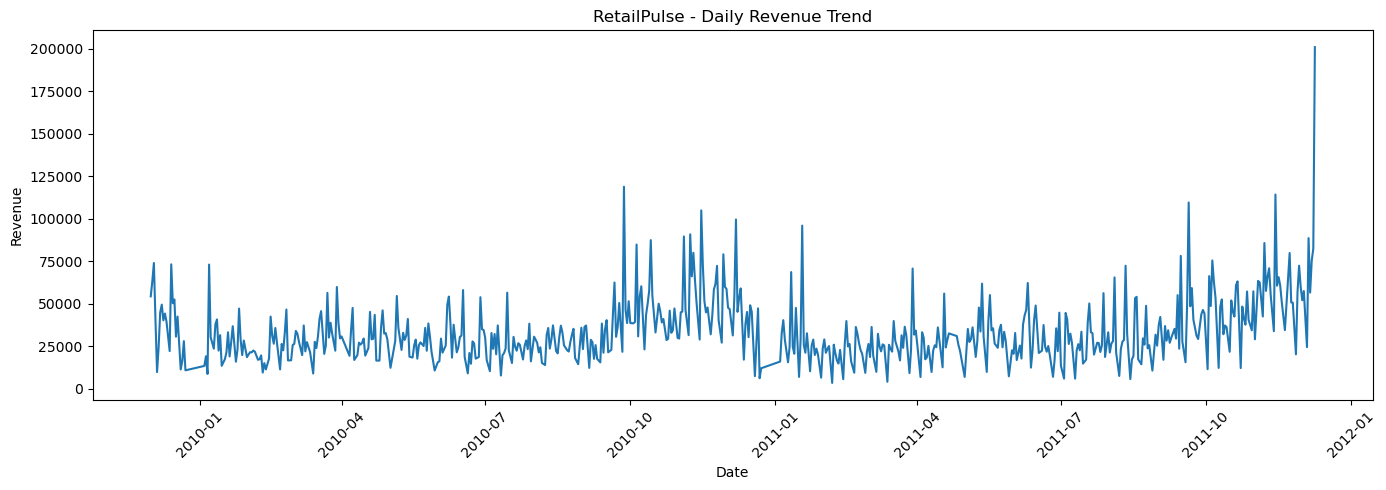

In [23]:

import matplotlib.pyplot as plt
import pandas as pd

# Date ko datetime format mein convert karo
daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])

# Daily revenue trend
plt.figure(figsize=(14, 5))
plt.plot(
    daily_sales["Date"],
    daily_sales["Total_Revenue"]
)
plt.title("RetailPulse - Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [24]:

# Check missing calendar dates
daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])

all_dates = pd.date_range(
    start=daily_sales["Date"].min(),
    end=daily_sales["Date"].max(),
    freq="D"
)

missing_dates = all_dates.difference(daily_sales["Date"])

print("First date:", daily_sales["Date"].min())
print("Last date:", daily_sales["Date"].max())
print("Existing daily records:", len(daily_sales))
print("Missing calendar dates:", len(missing_dates))

print("\nFirst missing dates:")
print(missing_dates[:10])


First date: 2009-12-01 00:00:00
Last date: 2011-12-09 00:00:00
Existing daily records: 604
Missing calendar dates: 135

First missing dates:
DatetimeIndex(['2009-12-12', '2009-12-19', '2009-12-24', '2009-12-25',
               '2009-12-26', '2009-12-27', '2009-12-28', '2009-12-29',
               '2009-12-30', '2009-12-31'],
              dtype='datetime64[ns]', freq=None)


In [25]:

# All transaction dates
all_transaction_dates = pd.to_datetime(
    df_clean["InvoiceDate"].dt.date
).drop_duplicates()

# Missing dates ko transaction dates se compare karo
missing_date_series = pd.Series(missing_dates)

dates_with_transactions = missing_date_series[
    missing_date_series.isin(all_transaction_dates)
]

dates_without_transactions = missing_date_series[
    ~missing_date_series.isin(all_transaction_dates)
]

print(
    "Missing dates with transactions:",
    len(dates_with_transactions)
)

print(
    "Missing dates without any transaction:",
    len(dates_without_transactions)
)

print("\nDates with transactions:")
print(dates_with_transactions.head(10))


Missing dates with transactions: 0
Missing dates without any transaction: 135

Dates with transactions:
Series([], dtype: datetime64[ns])


In [26]:

# Weekday-wise sales analysis
daily_sales["Weekday"] = daily_sales["Date"].dt.day_name()

weekday_sales = (
    daily_sales.groupby("Weekday")
    .agg(
        Average_Revenue=("Total_Revenue", "mean"),
        Average_Quantity=("Total_Quantity", "mean"),
        Days_Recorded=("Date", "count")
    )
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
    .round(2)
)

display(weekday_sales)


,Average_Revenue,Average_Quantity,Days_Recorded
Weekday,,,
Monday,38106.04,21604.72,94
Tuesday,39212.98,20605.38,104
Wednesday,33542.73,19228.52,104
Thursday,40730.22,22528.31,103
Friday,33574.84,16956.84,99
Saturday,9803.05,5119.00,1
Sunday,18173.20,10376.94,99


In [27]:

# Original transaction dates ka weekday distribution
transaction_dates = pd.to_datetime(
    df_clean["InvoiceDate"].dt.date
)

weekday_counts = (
    transaction_dates.dt.day_name()
    .value_counts()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ], fill_value=0)
)

display(weekday_counts.rename("Transaction_Rows_By_Weekday").to_frame())


,Transaction_Rows_By_Weekday
InvoiceDate,
Monday,183698
Tuesday,191972
Wednesday,177444
Thursday,196188
Friday,150310
Saturday,402
Sunday,133017


In [28]:

# Daily sales ko complete calendar par align karo
daily_sales["Date"] = pd.to_datetime(daily_sales["Date"])

daily_sales_full = (
    daily_sales
    .drop(columns=["Weekday"], errors="ignore")
    .set_index("Date")
    .reindex(all_dates)
)

# Missing dates ke sales metrics ko temporarily zero se fill karo
sales_columns = [
    "Total_Quantity",
    "Total_Revenue",
    "Total_Invoices"
]

daily_sales_full[sales_columns] = (
    daily_sales_full[sales_columns].fillna(0)
)

daily_sales_full.index.name = "Date"
daily_sales_full = daily_sales_full.reset_index()

print("Rows before:", len(daily_sales))
print("Rows after:", len(daily_sales_full))
print("Remaining missing values:")
print(daily_sales_full[sales_columns].isnull().sum())

display(daily_sales_full.head())
display(daily_sales_full.tail())


Rows before: 604
Rows after: 739
Remaining missing values:
Total_Quantity    0
Total_Revenue     0
Total_Invoices    0
dtype: int64


,Date,Total_Quantity,Total_Revenue,Total_Invoices
0,2009-12-01,26098.0,54351.23,119.0
1,2009-12-02,31804.0,63172.58,115.0
2,2009-12-03,49221.0,73972.45,124.0
3,2009-12-04,21210.0,40582.32,89.0
4,2009-12-05,5119.0,9803.05,30.0


,Date,Total_Quantity,Total_Revenue,Total_Invoices
734,2011-12-05,44497.0,88620.84,127.0
735,2011-12-06,30377.0,56558.83,115.0
736,2011-12-07,41789.0,75315.55,106.0
737,2011-12-08,35010.0,82371.55,120.0
738,2011-12-09,93950.0,200918.98,44.0


In [29]:

from pathlib import Path

# Project root aur output path
PROJECT_ROOT = Path.cwd().parent
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "daily_sales.csv"

# Save processed daily sales
daily_sales_full.to_csv(OUTPUT_PATH, index=False)

print("Dataset saved successfully!")
print("File path:", OUTPUT_PATH)
print("Rows saved:", len(daily_sales_full))
print("Columns:", daily_sales_full.columns.tolist())


Dataset saved successfully!
File path: c:\Users\mukes\Downloads\OneDrive\Documents\RetailPulse\data\processed\daily_sales.csv
Rows saved: 739
Columns: ['Date', 'Total_Quantity', 'Total_Revenue', 'Total_Invoices']


In [30]:

# Saved CSV ko dobara read karke verify karo
saved_df = pd.read_csv(
    OUTPUT_PATH,
    parse_dates=["Date"]
)

print("File loaded successfully!")
print("Shape:", saved_df.shape)
print("Missing values:")
print(saved_df.isnull().sum())

display(saved_df.head())


File loaded successfully!
Shape: (739, 4)
Missing values:
Date              0
Total_Quantity    0
Total_Revenue     0
Total_Invoices    0
dtype: int64


,Date,Total_Quantity,Total_Revenue,Total_Invoices
0,2009-12-01,26098.0,54351.23,119.0
1,2009-12-02,31804.0,63172.58,115.0
2,2009-12-03,49221.0,73972.45,124.0
3,2009-12-04,21210.0,40582.32,89.0
4,2009-12-05,5119.0,9803.05,30.0


In [31]:
print("Dataset Shape:", daily_sales_full.shape)
print("\nDate Range:")
print(daily_sales_full["Date"].min(), "to", daily_sales_full["Date"].max())

print("\nSummary Statistics:")
display(daily_sales_full[["Total_Quantity", "Total_Revenue", "Total_Invoices"]].describe())

Dataset Shape: (739, 4)

Date Range:
2009-12-01 00:00:00 to 2011-12-09 00:00:00

Summary Statistics:


,Total_Quantity,Total_Revenue,Total_Invoices
count,739.000000,739.000000,739.000000
mean,15162.583221,27708.571066,54.232747
std,13037.040069,21649.142136,34.057459
min,0.000000,0.000000,0.000000
25%,8122.500000,14763.205000,36.000000
50%,13980.000000,25916.150000,57.000000
75%,20499.000000,37871.860000,75.000000
max,125489.000000,200918.980000,153.000000


top_10_days = daily_sales_full.sort_values(
    by="Total_Revenue",
    ascending=False
).head(10)

display(top_10_days)

In [32]:
top_10_days = daily_sales_full.sort_values(
    by="Total_Revenue",
    ascending=False
).head(10)

display(top_10_days)

,Date,Total_Quantity,Total_Revenue,Total_Invoices
738,2011-12-09,93950.0,200918.980,44.0
300,2010-09-27,125489.0,118838.470,95.0
713,2011-11-14,47236.0,114237.400,107.0
658,2011-09-20,43683.0,109553.900,70.0
349,2010-11-15,37969.0,104910.960,103.0
371,2010-12-07,25180.0,99553.850,84.0
413,2011-01-18,82964.0,95947.730,41.0
342,2010-11-08,32397.0,90826.501,82.0
338,2010-11-04,60269.0,89585.630,132.0
734,2011-12-05,44497.0,88620.840,127.0


In [33]:
target_date = pd.Timestamp("2011-12-09")

day_sales = sales_df[
    sales_df["InvoiceDate"].dt.normalize() == target_date
].copy()

top_products = (
    day_sales.groupby("Description")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
)

print("Transactions on:", target_date.date())
print("Total transaction rows:", len(day_sales))
display(top_products)

Transactions on: 2011-12-09
Total transaction rows: 1619


,Total_Quantity,Total_Revenue
Description,,
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
DOTCOM POSTAGE,2,2647.34
BLACK RECORD COVER FRAME,189,669.57
PAPER CHAIN KIT 50'S CHRISTMAS,114,591.90
RABBIT NIGHT LIGHT,174,571.41
HOT WATER BOTTLE TEA AND SYMPATHY,64,538.56
ASSORTED COLOUR MINI CASES,84,533.40
HOME SWEET HOME BLACKBOARD,144,469.44
HOT WATER BOTTLE KEEP CALM,64,437.04


In [34]:
target_date = pd.Timestamp("2011-12-09")

product_transactions = sales_df[
    (sales_df["InvoiceDate"].dt.normalize() == target_date)
    & (
        sales_df["Description"]
        == "PAPER CRAFT , LITTLE BIRDIE"
    )
]

display(
    product_transactions[
        ["Invoice", "StockCode", "Quantity", "Price", "Revenue", "Customer ID"]
    ]
)

print("Transaction rows:", len(product_transactions))
print("Total quantity:", product_transactions["Quantity"].sum())
print("Total revenue:", product_transactions["Revenue"].sum())
print("Unique invoices:", product_transactions["Invoice"].nunique())

,Invoice,StockCode,Quantity,Price,Revenue,Customer ID
1065882,581483,23843,80995,2.08,168469.6,16446.0


Transaction rows: 1
Total quantity: 80995
Total revenue: 168469.6
Unique invoices: 1


In [35]:
invoice_id = product_transactions["Invoice"].iloc[0]

invoice_details = df_clean[
    df_clean["Invoice"] == invoice_id
]

display(invoice_details)

print("Invoice ID:", invoice_id)
print("Total rows in invoice:", len(invoice_details))
print("Total quantity:", invoice_details["Quantity"].sum())
print("Total revenue:", invoice_details["Revenue"].sum())

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6


Invoice ID: 581483
Total rows in invoice: 1
Total quantity: 80995
Total revenue: 168469.6


In [36]:
invoice_details[
    [
        "Invoice",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "Price",
        "Customer ID",
        "Country",
        "Revenue"
    ]
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,168469.6


In [37]:
daily_sales_full["Date"] = pd.to_datetime(
    daily_sales_full["Date"]
)

spike_date = pd.Timestamp("2011-12-09")

print("Revenue on spike date:")
print(
    daily_sales_full.loc[
        daily_sales_full["Date"] == spike_date,
        ["Date", "Total_Quantity", "Total_Revenue", "Total_Invoices"]
    ]
)

print("\nRevenue on previous 7 days:")
display(
    daily_sales_full[
        (daily_sales_full["Date"] >= spike_date - pd.Timedelta(days=7))
        & (daily_sales_full["Date"] < spike_date)
    ][["Date", "Total_Revenue"]]
)

Revenue on spike date:
          Date  Total_Quantity  Total_Revenue  Total_Invoices
738 2011-12-09         93950.0      200918.98            44.0

Revenue on previous 7 days:


,Date,Total_Revenue
731,2011-12-02,57476.48
732,2011-12-03,0.00
733,2011-12-04,24477.47
734,2011-12-05,88620.84
735,2011-12-06,56558.83
736,2011-12-07,75315.55
737,2011-12-08,82371.55


In [38]:
daily_sales_full["Revenue_Spike_Flag"] = (
    daily_sales_full["Date"] == pd.Timestamp("2011-12-09")
)

display(
    daily_sales_full[
        daily_sales_full["Revenue_Spike_Flag"]
    ][
        ["Date", "Total_Quantity", "Total_Revenue",
         "Total_Invoices", "Revenue_Spike_Flag"]
    ]
)

,Date,Total_Quantity,Total_Revenue,Total_Invoices,Revenue_Spike_Flag
738,2011-12-09,93950.0,200918.98,44.0,True


In [39]:
OUTPUT_PATH = PROJECT_ROOT / "data" / "processed" / "daily_sales.csv"

daily_sales_full.to_csv(OUTPUT_PATH, index=False)

print("Updated dataset saved successfully!")
print("Shape:", daily_sales_full.shape)
print("Columns:", daily_sales_full.columns.tolist())

Updated dataset saved successfully!
Shape: (739, 5)
Columns: ['Date', 'Total_Quantity', 'Total_Revenue', 'Total_Invoices', 'Revenue_Spike_Flag']


In [40]:
saved_df = pd.read_csv(
    OUTPUT_PATH,
    parse_dates=["Date"]
)

print("Shape:", saved_df.shape)
print("\nMissing values:")
print(saved_df.isnull().sum())

print("\nFlagged records:")
display(
    saved_df[saved_df["Revenue_Spike_Flag"] == True]
)

Shape: (739, 5)

Missing values:
Date                  0
Total_Quantity        0
Total_Revenue         0
Total_Invoices        0
Revenue_Spike_Flag    0
dtype: int64

Flagged records:


,Date,Total_Quantity,Total_Revenue,Total_Invoices,Revenue_Spike_Flag
738,2011-12-09,93950.0,200918.98,44.0,True
